## Homework 2

### Aggregate daily weather data

We first use groupby to aggregate multiple columns from the hourly data by day:


In [10]:
import pandas as pd
import numpy as np

hourly = pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Science\class_1\weather_forecast\weather_actual.csv")
hourly["timestamp"] = pd.to_datetime(hourly["time"])
#simpler column names
hourly= hourly.rename(columns={
    "temperature_2m (°C)": "temperature",
    "relative_humidity_2m (%)": "humidity",
    "precipitation (mm)": "precipitation",
    "pressure_msl (hPa)": "pressure_sea_level",
    "wind_speed_10m (km/h)": "wind_speed"
})
hourly.head()

,time,temperature,humidity,precipitation,weather_code (wmo code),pressure_sea_level,wind_speed,timestamp
0,2016-10-09T00:00,7.6,90,0.0,3,1022.3,12.3,2016-10-09 00:00:00
1,2016-10-09T01:00,7.7,90,0.0,3,1022.3,13.4,2016-10-09 01:00:00
2,2016-10-09T02:00,7.9,90,0.2,51,1021.9,13.6,2016-10-09 02:00:00
3,2016-10-09T03:00,8.1,91,0.3,51,1021.6,12.5,2016-10-09 03:00:00
4,2016-10-09T04:00,8.3,92,0.2,51,1021.5,12.3,2016-10-09 04:00:00


In [19]:
hourly['date']= pd.to_datetime(hourly['time']).dt.date
daily = hourly.groupby("date").agg({
    "temperature": "max",
    "humidity": "mean",
    "precipitation": "sum",
    "pressure_sea_level": "mean",
    "wind_speed": "mean"
}).reset_index()

daily.columns = [
    "date",
    "max_temperature",
    "humidity",
    "precipitation",
    "pressure",
    "wind_speed"
]
daily['date'] = pd.to_datetime(daily["date"])
daily['month'] = daily["date"].dt.month
daily.head()

,date,max_temperature,humidity,precipitation,pressure,wind_speed,month
0,2016-10-09,10.6,85.041667,1.4,1022.858333,9.729167,10
1,2016-10-10,11.7,81.208333,0.0,1023.716667,5.354167,10
2,2016-10-11,9.3,91.791667,3.3,1020.841667,9.466667,10
3,2016-10-12,9.0,87.541667,1.4,1022.504167,14.920833,10
4,2016-10-13,7.6,80.750000,0.8,1022.875000,15.770833,10


To save time on future assignments, let us save the daily numbers as a csv file

In [20]:
daily.to_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Science\data\wheather_daily.csv")

## Task 1

Create a boxplot for the average daily precipitation by month.

* Does it look reasonable ?
* How could one deal with such extremely right-skewed distributions
* (**moodle**) What is the IQR for the month of October?

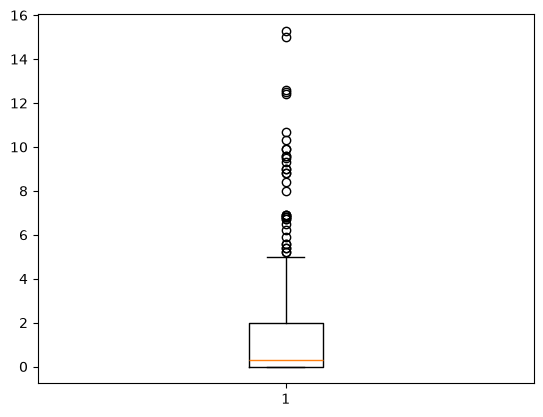

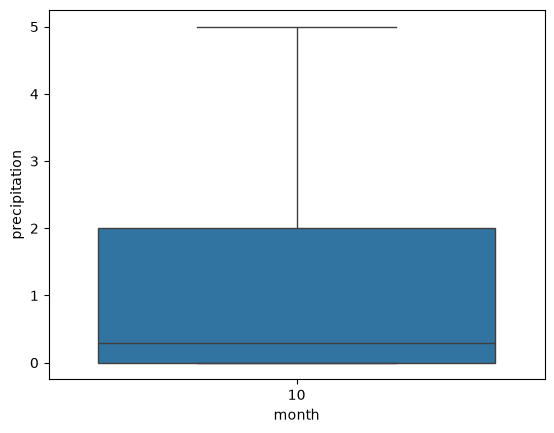

0.0 2.0
3655 382


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.boxplot(x=daily.loc[daily["month"]==10,'precipitation'])
plt.show()
plt.clf()

sns.boxplot(
    data=daily.loc[daily["month"]==10],
    x="month",
    y="precipitation",
    showfliers=False
)
plt.show()


first_quartile_oct =  np.percentile(daily.loc[daily["month"]==10,"precipitation"],25)
third_quartile_oct =  np.percentile(daily.loc[daily["month"]==10,"precipitation"],75)
IQR = third_quartile_oct -first_quartile_oct
print(first_quartile_oct, third_quartile_oct )
outlier_ceiling = third_quartile_oct+1.5*IQR
no_outliers = daily[daily["precipitation"]<outlier_ceiling]
cut=len(daily)-len(no_outliers)
print(len(daily), cut)
#cannot just cut outliers from the plot as I would loose a lot of data





## Task 2

### Measure of Variation

* Would you prefer IQR or the stdev as a measure that quantifies the overall variability?
St_dev as the IQR would cut too much datapoints.
* Did you know that there are two different definitions of stedv.?:
    * Sample stdev.
    * Population stdev.

* (**moodle**) Compute the (population) stdev. for daily rainfall in October.

In [43]:
import numpy as np

pop_stdev = np.std(daily.loc[daily["month"]==10,"precipitation"], ddof=0)
print(pop_stdev)




2.853429987453861


## Task 3

### Quantiles

1. How reliably do you think can we compute/estimate quantiles from empirical data ? Might that depend on which quantile?
2. (**moodle**) Calculate the 90th percentile for daily rain (overall). 

In [46]:
ptile90 =  np.percentile(daily["precipitation"],90)
ptile90

np.float64(5.1000000000000005)

## Task 4

* Compute the median precipitation
* Add a "biblical flood" to your data, i.e. add one extreme outlier to your data: $precipitation = 10000$.
* Compute the median precipitation again
* (**moodle**) What is the difference in these two numbers ?



In [52]:
med_prec = np.median(daily["precipitation"])
prec_basic = daily["precipitation"].to_numpy()
precipitation_extra= np.append(prec_basic,10000)
med_extra = np.median(precipitation_extra)
print(
med_prec,
med_extra,
med_extra-med_prec)

0.2 0.2 0.0
